In [1]:
from plotter import makeplot

In [82]:
#________________________
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, AutoMinorLocator, LogLocator
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib import ticker 
def makeplot(fun, plotsettings):
    """
    Pass a dictionary plotsettings to create a generic plot. 
    

    
    Usage:
    
        - Do not pass figsize if you want to use the old figure. 
        - For plt.plot use 'x' and 'y' in 'plot' word for providing data i.e.:
                {'plot': {'x': [1,2,3], 'y': [3,4,5]}
    
    Example 1 (plt.plot):
        settings2 = {
            'figure': {'figsize': (4,4)},
            'plot':{'x':[4,4,4,5,3], 'y': [2,3,1,4,5], 'color':'green', 'alpha': 0.4}, 

            'xlabel': 'sigma1_traceAvlog10', 
            'xlim': [0.5,7.8],
            'ylabel': 'Frequency',
            'ylim': [1,2],
            'legend': {'frameon': False}
        }

        makeplot(plt.plot, settings2)
    
    
    """
    
    if 'figure' in plotsettings.keys(): plt.figure(**plotsettings['figure'])

    ax = plt.gca()

    if 'inset_axes' in plotsettings.keys(): inset_axes(ax, **plotsettings['inset_axes'])
    
    
    #_________Make plot and set defaults___________
    if 'plot' in plotsettings.keys(): 
        #-------Matplotlib's plt.plot needs a special hack----------
        if fun.__name__ == 'plot':
            x = plotsettings['plot'].pop('x')
            y = plotsettings['plot'].pop('y')
            
            fun(x, y, **plotsettings['plot'])
            
            plotsettings['plot']['x'] = x
            plotsettings['plot']['y'] = y
        #-------Else runs for plt.hist, plt.scatter etc.-------------
        else:
            fun(**plotsettings['plot'])
        if 'xscale' in plotsettings['plot'].keys():
            if plotsettings['plot']['xscale'] == 'log': ax.xaxis.set_major_locator(LogLocator(numticks=4)) 
        if 'yscale' in plotsettings['plot'].keys():
            if plotsettings['plot']['yscale'] == 'log': ax.yaxis.set_major_locator(LogLocator(numticks=3))

    ax.tick_params(axis='both', which = 'both', direction='in')
    ax.xaxis.set_major_locator(MaxNLocator(integer=False, prune='both', nbins=4))
    ax.yaxis.set_major_locator(MaxNLocator(integer=False, prune='both', nbins=4))
    
   
    #_____Changes to defaults____

    
    if 'xlim' in plotsettings.keys(): plt.xlim(plotsettings['xlim'])
    if 'ylim' in plotsettings.keys(): plt.ylim(plotsettings['ylim'])
    if 'xlabel' in plotsettings.keys(): plt.xlabel(plotsettings['xlabel'])
    if 'ylabel' in plotsettings.keys(): plt.ylabel(plotsettings['ylabel'])
    if 'xscale' in plotsettings.keys(): plt.xscale(plotsettings['xscale'])
    if 'yscale' in plotsettings.keys(): plt.yscale(plotsettings['yscale'])
    
    if 'legend' in plotsettings.keys(): plt.legend(**plotsettings['legend'])
    if 'tick_params' in plotsettings.keys(): ax.tick_params(**plotsettings['tick_params'])
    if 'xaxis.set_major_locator' in plotsettings.keys():ax.xaxis.set_major_locator(**plotsettings['xaxis.set_major_locator'])
    if 'yaxis.set_major_locator' in plotsettings.keys():ax.yaxis.set_major_locator(**plotsettings['yaxis.set_major_locator'])

    if 'axvline' in plotsettings.keys(): ax.axvline(**plotsettings['axvline'])
    if 'annotate' in plotsettings.keys(): ax.annotate(**plotsettings['annotate'])
    if 'colorbar' in plotsettings.keys(): plt.colorbar(**plotsettings['colorbar'])
    if 'savefig' in plotsettings.keys(): plt.savefig(**plotsettings['savefig'])
   
    return 

def makebands(plotsettings, symmetrypoints  = [3,4,5]):
    makeplot(plt.plot, plotsettings);
    for entry in symmetrypoints:
        plt.axvline(x = entry)
    return 


In [ ]:
symm = { 'gamma': [0,0,0],
        'R': [0.5, 0.5, 0.5],
        


}

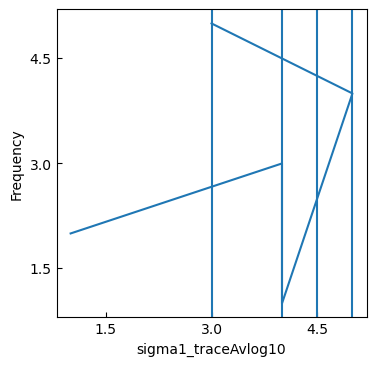

In [76]:
def makebands(plotsettings, symmetrypoints  = [3,4,5]):
    makeplot(plt.plot, plotsettings);
    for entry in symmetrypoints:
        plt.axvline(x = entry)
    return 





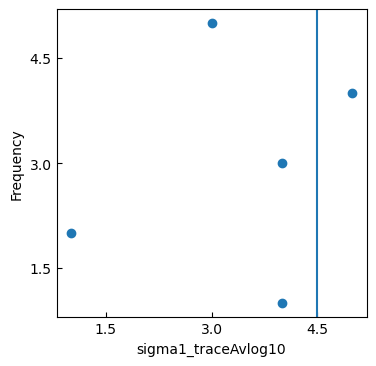

In [83]:
data = list(range(15))
settings = {
    'figure': {'figsize': (8,3)},
    'plot':{'x':[1,2,3,3], 'y': [3,4,3,5],  'color':'blue', 'alpha': 0.4}, 
    
    'xlabel': 'sigma1_traceAvlog10', 
    #'xlim': [0.5,7.8],
    'ylabel': 'Frequency',
    #'ylim': [1,2],
    'legend': {'frameon': False}
}

settings2 = {
    'figure': {'figsize': (4,4)},
    'plot':{'x':[1,4,4,5,3], 'y': [2,3,1,4,5]}, 
    
    
    'axvline': {'x':[4.5]},
    'xlabel': 'sigma1_traceAvlog10', 
    #'xlim': [0.5,7.8],
    'ylabel': 'Frequency',
    #'ylim': [1,2],
    #'legend': {'frameon': False}
}

makeplot(plt.scatter, settings2)


In [88]:
settings2

{'figure': {'figsize': (4, 4)},
 'plot': {'x': [1, 4, 4, 5, 3], 'y': [2, 3, 1, 4, 5]},
 'axvline': {'x': [4.5]},
 'xlabel': 'sigma1_traceAvlog10',
 'ylabel': 'Frequency'}

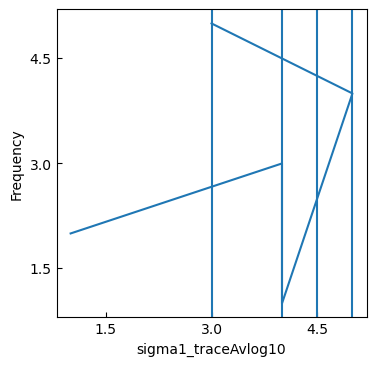

In [87]:
makebands(settings2, symmetrypoints = [3,4,5])

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


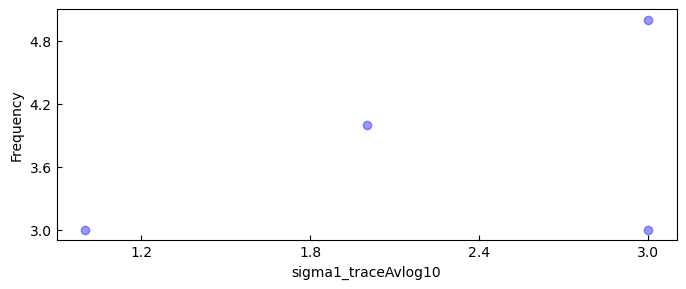

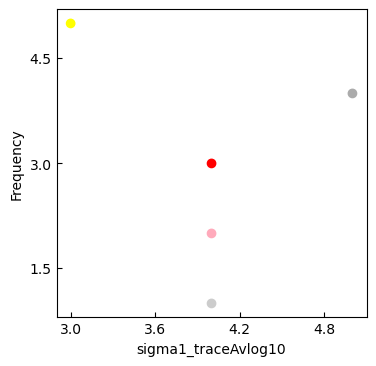

In [64]:
makeplot(plt.scatter, settings)
makeplot(plt.scatter, settings2)

((0.12156862745098039, 0.4666666666666667, 0.7058823529411765),
 (1.0, 0.4980392156862745, 0.054901960784313725),
 (0.17254901960784313, 0.6274509803921569, 0.17254901960784313),
 (0.8392156862745098, 0.15294117647058825, 0.1568627450980392),
 (0.5803921568627451, 0.403921568627451, 0.7411764705882353))

TypeError: plot got an unexpected keyword argument 'x'

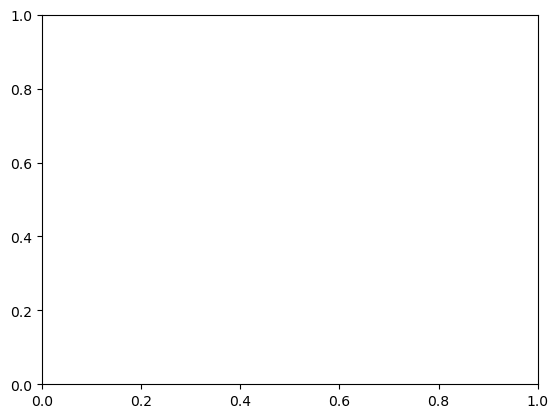

In [8]:
import matplotlib.pyplot as plt

plotsettings = {'plot': {'x': [1,2,3], 'y':[3,4,5]},
                'xlim': [1,4], 
               'ylim': [3,5]}

makeplot(plt.plot, plotsettings)